# Maximal scattering of a PEC structure at a fixed quality factor

Lossless counterpart of `maxScatFixQ.ipynb`: the same 2:1 plate, $ka = 1$ at 2.45 GHz, plane wave polarized along the shorter side
($E_0 = 1$ kV/m), scattered voltage $x = V_\mathrm{sca} = -Z_0 I$ as the degree of freedom, but the structure is perfectly conducting. A
structure is a subset of enabled basis functions satisfying only
$$Z_{0,\mathcal{AA}} I_\mathcal{A} = V_\mathcal{A}, \qquad I_i = 0 \text{ elsewhere},$$
with no lossy matrix, so every structure satisfies $w_i = I_i^*(V - Z_0 I)_i = 0$.

**Why the stored energy is needed.** Without loss, the Lagrangian of the power-conservation constraints is
$A(\lambda) = W^H\left[(\lambda_\mathrm{re} - \tfrac12) R_0 + \lambda_\mathrm{im} X_0\right] W$ (globally) with $R_0$ of low rank at $ka = 1$; the reactive
term is indefinite. $A(\lambda)$ is never positive definite (the check below finds no PSD point), so the dual gives no bound; without loss, only the
stored energy limits the resonant enhancement of the scattered power. The fixed
$Q_W = I^H \omega W I / (2 I^H R_0 I) = Q_0$ constraint with $B = \omega W/(2Q_0) - R_0$ and multiplier $\mu > 0$ supplies the positive definite part:
$$\lambda_\mathrm{re} = \tfrac12 + \mu,\ \lambda_\mathrm{im} = 0 \quad\Rightarrow\quad A = \frac{\mu}{2 Q_0} W^H \omega W\, W \succ 0 ,$$
a dual feasible start. The bound exists only with $\mu \geq 0$, so it bounds every PEC structure with $Q_W \leq Q_0$; there is no bound
without the constraint.

Steps: the Pareto front of the bound against $Q_0$ (global constraints) compared with copper, GCD (20 iterations) and the full local bound at
selected $Q_0$, and the inference of PEC structures from every dual.

In [1]:
import contextlib
import copy
import io
import time

import matplotlib.pyplot as plt
import numpy as np
import scipy.io as sio
import scipy.linalg as la
import scipy.sparse as sp
from matplotlib.collections import LineCollection, PolyCollection
from matplotlib.colors import LogNorm
from scipy.optimize import least_squares

from dolphindes.cvxopt import DenseSharedProjQCQP, OptimizationHyperparameters
from dolphindes.cvxopt.gcd import GCDHyperparameters

In [2]:
matrixSet = "patch21ka1" # 2:1 plate, ka = 1; omW and the mesh exist for this set only (exportOmWpatch21ka1.m)

# Physical constants
epsilon_0 = 8.854e-12 # F/m
mu_0 = 4e-7 * np.pi # H/m
c = 1/np.sqrt(epsilon_0 * mu_0) # speed of light in vacuum
eta_0 = np.sqrt(mu_0/epsilon_0) # free-space impedance

E0 = 1e3 # plane wave amplitude in V/m

frequency = 2.45e9 # frequency in Hz
omega = 2 * np.pi * frequency # angular frequency

copper_conductivity = 5.96e7 # S/m, only for the comparison with copper
delta = np.sqrt(2 / (omega * mu_0 * copper_conductivity)) # skin depth in m
Zs = (1 + 1j) / (copper_conductivity * delta) # surface impedance

In [3]:
def Msym(M):
    return(0.5*(M.conj().T + M))

# Load matrices from text files (original RWG basis, no Cholesky transformation)
R0 = Msym(np.loadtxt(f"R0_{matrixSet}.txt", delimiter=',')) # radiated power matrix
X0 = Msym(np.loadtxt(f"X0_{matrixSet}.txt", delimiter=',')) # reactive power matrix
omW = Msym(np.loadtxt(f"omW_{matrixSet}.txt", delimiter=',')) # stored energy matrix, omega (Wm + We) = I^H omW I / 4
Vinc = E0*np.loadtxt(f"V_{matrixSet}.txt", delimiter=',').astype(complex) # voltage excitation vector

Ndes = R0.shape[0] # number of design variables
print(f"Matrix set: {matrixSet}, number of design variables: {Ndes}")

Z0 = R0 + 1j*X0 # free-space impedance matrix, the PEC system matrix

def evalObj(Ivec):
    # scattered (radiated) power
    return(0.5*np.real(Ivec.conj() @ R0 @ Ivec))

def evalQW(Ivec):
    # Q_W = omega (Wm + We) / Prad, the Q of a self-resonant current
    return(np.real(Ivec.conj() @ omW @ Ivec)/(2*np.real(Ivec.conj() @ R0 @ Ivec)))

def evalQ(Ivec):
    # Q = 2 omega max(Wm, We) / Prad (tuned)
    return((np.real(Ivec.conj() @ omW @ Ivec) + np.abs(np.real(Ivec.conj() @ X0 @ Ivec)))/(2*np.real(Ivec.conj() @ R0 @ Ivec)))

def exactCurrent(keep):
    # PEC structure: Z0[A, A] I_A = V_A on the kept basis functions, I = 0 elsewhere
    I = np.zeros(Ndes, dtype=complex)
    if np.any(keep):
        I[keep] = np.linalg.solve(Z0[np.ix_(keep, keep)], Vinc[keep])
    return I

# full plate performance
Ifull = np.linalg.solve(Z0, Vinc)
Pfull = evalObj(Ifull)
print(f"Objective for full plate: {Pfull:.6e} W, Q_W {evalQW(Ifull):.2f}, Q {evalQ(Ifull):.2f}")

lamR = np.linalg.eigvalsh(R0)
QWmin = 1/(2*la.eigh(R0, omW, eigvals_only=True).max()) # smallest Q_W of any current on the plate
print(f"rank R0 (eig > 1e-10 max) = {np.count_nonzero(lamR > 1e-10*lamR.max())} of {Ndes}, "
      f"eig(omW) in [{np.linalg.eigvalsh(omW).min():.3e}, {np.linalg.eigvalsh(omW).max():.3e}], min Q_W = {QWmin:.2f}")

# reference: lossless resonant electric dipole, sigma_sca = 3 lambda^2 / (2 pi)
Pdip = 3*(c/frequency)**2/(2*np.pi) * E0**2/(2*eta_0)
print(f"resonant dipole scattered power: {Pdip:.4f} W")

Matrix set: patch21ka1, number of design variables: 233
Objective for full plate: 4.113803e-02 W, Q_W 10.31, Q 18.40
rank R0 (eig > 1e-10 max) = 29 of 233, eig(omW) in [2.423e-05, 1.533e-02], min Q_W = 4.33
resonant dipole scattered power: 9.4884 W


104 nodes, 168 triangles, plate 35.05 x 17.00 mm


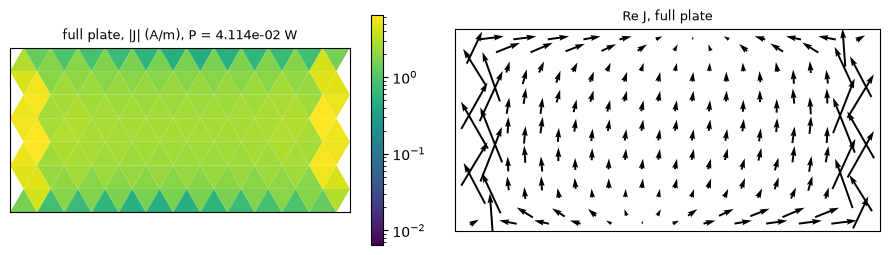

In [4]:
# mesh of the operators (exportOmWpatch21ka1.m): bf[n] = [T+, T-, edge node 1, edge node 2], 0 based
mesh = sio.loadmat(f"mesh_{matrixSet}.mat")
nodes, tria, bf = mesh["nodes"], mesh["triangles"], mesh["bf"]
edgeLen = np.linalg.norm(nodes[bf[:, 2]] - nodes[bf[:, 3]], axis=1)
e1, e2 = nodes[tria[:, 1]] - nodes[tria[:, 0]], nodes[tria[:, 2]] - nodes[tria[:, 0]]
triArea = 0.5*np.abs(e1[:, 0]*e2[:, 1] - e1[:, 1]*e2[:, 0])
triCent = nodes[tria].mean(axis=1)
freeNode = np.array([[np.setdiff1d(tria[t], bf[n, 2:])[0] for t in bf[n, :2]] for n in range(Ndes)]) # free vertices of T+, T-
print(f"{len(nodes)} nodes, {len(tria)} triangles, plate {np.ptp(nodes[:, 0])*1e3:.2f} x {np.ptp(nodes[:, 1])*1e3:.2f} mm")

def currentDensity(I):
    # RWG current density at the triangle centroids, J = I_n l_n rho / (2 A)
    J = np.zeros((len(tria), 2), dtype=complex)
    for s, sgn in [(0, 1), (1, -1)]:
        rho = sgn*(triCent[bf[:, s]] - nodes[freeNode[:, s]])
        np.add.at(J, bf[:, s], (I*edgeLen/(2*triArea[bf[:, s]]))[:, None]*rho)
    return J

def plotStructure(ax, keep, I, title=""):
    # metal triangles colored by |J| (log); removed RWG functions between metal triangles are slots (red), void triangles white
    metal = np.zeros(len(tria), dtype=bool)
    metal[bf[keep, :2].ravel()] = True
    J = np.linalg.norm(np.abs(currentDensity(I)), axis=1)
    pc = PolyCollection(nodes[tria[metal]], array=np.maximum(J[metal], 1e-3*J.max()), cmap='viridis',
                        norm=LogNorm(1e-3*J.max(), J.max()), edgecolors='none')
    ax.add_collection(pc)
    ax.add_collection(PolyCollection(nodes[tria[~metal]], facecolors='white', edgecolors='0.85', linewidths=0.3))
    slot = ~keep & metal[bf[:, 0]] & metal[bf[:, 1]]
    ax.add_collection(LineCollection(nodes[bf[slot, 2:]], colors='r', linewidths=1.5))
    ax.set_xlim(nodes[:, 0].min(), nodes[:, 0].max()); ax.set_ylim(nodes[:, 1].min(), nodes[:, 1].max())
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=9)
    return pc

def plotDensity(ax, d, title=""):
    # inferred density on the RWG edges
    lc = LineCollection(nodes[bf[:, 2:]], array=np.log10(np.maximum(d, 1e-6)), cmap='viridis', linewidths=2.5)
    lc.set_clim(-6, 0)
    ax.add_collection(lc)
    ax.set_xlim(nodes[:, 0].min(), nodes[:, 0].max()); ax.set_ylim(nodes[:, 1].min(), nodes[:, 1].max())
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=9)
    return lc

fig, axes = plt.subplots(1, 2, figsize=(9, 2.6))
plt.colorbar(plotStructure(axes[0], np.ones(Ndes, dtype=bool), Ifull, f"full plate, |J| (A/m), P = {Pfull:.3e} W"), ax=axes[0])
axes[1].quiver(*triCent.T, *np.real(currentDensity(Ifull)).T, angles='xy', pivot='mid')
axes[1].set_aspect('equal'); axes[1].set_xticks([]); axes[1].set_yticks([]); axes[1].set_title("Re J, full plate", fontsize=9)
plt.tight_layout(); plt.show()

## QCQP for the PEC structure

$x = V_\mathrm{sca}$, $I = -W x$, $W = Z_0^{-1}$; the objective $A_0 = -\tfrac12 W^H R_0 W$ and the projector constraints
$\operatorname{Re}\sum_i p_i^* w_i = \operatorname{Re}(-x^H P W x - x^H W^H P^H V) = 0$, i.e. the shared projector form with
$$A_1 = \mathbf 1, \qquad A_2 = W, \qquad s_1 = -\tfrac12 V$$
(`maxScatFixQ.ipynb` with $Z_\mathrm{mat} = 0$). The fixed $Q_W$ is the general constraint $B = \omega W/(2Q_0) - R_0$ with residual
$2P_\mathrm{rad}(1 - Q_W/Q_0)$ in watts. Strong duality, the hard case and the kernel completion $x^\star + V\alpha$ are treated as in
`maxScatFixQ.ipynb`. All projector multipliers are started from $\tfrac12 + \mu_0$ on the real power constraints and $\mu_0$ on $Q_W$.

In [5]:
print(f"cond(Z0) = {np.linalg.cond(Z0):.3e}")
W = np.linalg.inv(Z0) # Z0^{-1}
WH = W.conj().T

Obj = -0.5 * Msym(WH @ R0 @ W)
obj = np.zeros(Ndes, dtype=complex)
obj0 = 0.0
A1 = np.eye(Ndes)
A2 = W
s1 = -0.5 * Vinc
mu0 = 1.0 # initial multiplier of the Q_W constraint

def VtoI(Vsca):
    return(-W @ Vsca)

def localViolation(I):
    # pointwise w_i = I_i^* (V - Z0 I)_i, zero for any structure made of enabled basis functions
    return(np.conj(I)*(Vinc - Z0 @ I))

def qConstraint(Q0):
    # Re(-I^H B I) = I^H R0 I (1 - Q_W/Q0) = 0, B = omW/(2 Q0) - R0 (general constraint, x = Vsca, A2 = W)
    return dict(B_j=[omW/(2*Q0) - R0], s_2j=[np.zeros(Ndes, dtype=complex)], c_2j=np.array([0.0]))

def buildQCQP(Plist, Q0=None):
    return DenseSharedProjQCQP(Obj, obj, obj0, A1, s1, Plist, A2=A2, verbose=0, **({} if Q0 is None else qConstraint(Q0)))

def constraintRes(Q, x):
    # c_k(x) = Re(-x^H A_k x + 2 x^H F_k) + c_k for all constraints (W), zero for a feasible x
    res = np.real(-x.conj() @ Q._allA_at_v(x) + 2*x.conj() @ Q.Fs)
    res[Q.n_proj_constr:] += Q.c_2j
    return res

def completeKernel(Q, kerTol=1e-8, nStart=8, seed=0):
    # x = x* + V alpha on the near-kernel of L* (eig < kerTol max eig) with minimal constraint residual
    xs = Q.current_xstar
    lam, U = np.linalg.eigh(Msym(Q._get_total_A(Q.current_lags)))
    K = int(np.count_nonzero(lam < kerTol*lam[-1]))
    res0 = constraintRes(Q, xs)
    if K == 0:
        return xs, K, res0, res0
    V = U[:, :K]
    def fun(a):
        return constraintRes(Q, xs + V @ (a[:K] + 1j*a[K:]))/Q.current_dual
    def jac(a):
        # dc_k / d(Re, Im) alpha_j = 2 (Re, Im) v_j^H (F_k - A_k x)
        x = xs + V @ (a[:K] + 1j*a[K:])
        VG = V.conj().T @ (Q.Fs - Q._allA_at_v(x))
        return np.vstack([2*VG.real, 2*VG.imag]).T/Q.current_dual
    q = np.real(V[:, 0].conj() @ Q._allA_at_v(V[:, 0])) # c(x* + a v) = c(x*) - |a|^2 v^H A_k v for a single kernel vector
    scale = np.sqrt(np.abs(res0 @ q)/(q @ q))
    rng = np.random.default_rng(seed)
    a0 = [np.r_[scale, np.zeros(2*K - 1)]] + [scale*rng.standard_normal(2*K)/np.sqrt(K) for _ in range(nStart - 1)]
    sol = min((least_squares(fun, a, jac=jac, xtol=1e-15, ftol=1e-15, gtol=1e-15, max_nfev=200) for a in a0), key=lambda s: s.cost)
    x = xs + V @ (sol.x[:K] + 1j*sol.x[K:])
    return x, K, res0, constraintRes(Q, x)

def dualReport(name, Q, t=None):
    # bound, multiplier of the Q constraint, spectrum of L*, residuals at x* and after the kernel completion
    D = Q.current_dual
    lam = np.linalg.eigvalsh(Msym(Q._get_total_A(Q.current_lags)))
    x, K, res0, res1 = completeKernel(Q)
    I = VtoI(x)
    w = localViolation(I)
    mu = Q.current_lags[Q.n_proj_constr] if Q.n_gen_constr else np.nan
    gap = (D - evalObj(I))/D
    print(f"{name}: D {D:.6e} W, mu " + ("none" if np.isnan(mu) else f"{mu:+.3e}") + f", min eig L* / max {lam[0]/lam[-1]:.1e}, "
          f"kernel dim {K}, ||c||/D: x* {np.linalg.norm(res0)/D:.1e} -> completed {np.linalg.norm(res1)/D:.1e}, "
          f"(D - P(I))/D {gap:+.1e}, Q_W(I) {evalQW(I):.2f}, max|w_i| / |I^H V| {np.abs(w).max()/np.abs(I.conj() @ Vinc):.1e}"
          + ("" if t is None else f", {t:.1f}s"))
    return dict(D=D, mu=mu, lam=lam, K=K, x=x, res0=res0, res1=res1, gap=gap)


# checks: the Q residual of the full plate, positive definiteness without and with the Q_W constraint
PlistGlob = [sp.diags(q*np.ones(Ndes, dtype=complex)) for q in [1, 1j]] # global real and reactive power
Qn = buildQCQP(PlistGlob)
for lags in [np.array([1.0, 0.0]), np.array([0.5, 0.0]), np.array([1.0, 0.1])]:
    print(f"no Q_W constraint, lags {lags}: min eig A = {np.linalg.eigvalsh(Msym(Qn._get_total_A(lags)))[0]:+.3e}, "
          f"dual feasible {Qn.is_dual_feasible(lags)}")
for Q0 in [evalQW(Ifull), 2*evalQW(Ifull)]:
    Qt = buildQCQP(PlistGlob, Q0)
    lags = np.array([0.5 + mu0, 0.0, mu0])
    A = Msym(Qt._get_total_A(lags))
    print(f"Q0 {Q0:.3f}: Q residual of the full plate {constraintRes(Qt, -Z0 @ Ifull)[-1]:.6e} W "
          f"(2 Prad (1 - Q_W/Q0) = {2*Pfull*(1 - evalQW(Ifull)/Q0):.6e} W), start lags {lags}: "
          f"||A - mu0/(2 Q0) W^H omW W|| / ||A|| = {np.linalg.norm(A - mu0/(2*Q0)*Msym(WH @ omW @ W))/np.linalg.norm(A):.1e}, "
          f"min eig {np.linalg.eigvalsh(A)[0]:.3e}, dual feasible {Qt.is_dual_feasible(lags)}")

cond(Z0) = 6.327e+02
no Q_W constraint, lags [1. 0.]: min eig A = -2.234e-09, dual feasible False
no Q_W constraint, lags [0.5 0. ]: min eig A = -1.254e-09, dual feasible False
no Q_W constraint, lags [1.  0.1]: min eig A = -5.984e+01, dual feasible False
Q0 10.312: Q residual of the full plate 1.411985e-16 W (2 Prad (1 - Q_W/Q0) = 0.000000e+00 W), start lags [1.5 0.  1. ]: ||A - mu0/(2 Q0) W^H omW W|| / ||A|| = 9.5e-13, min eig 3.170e+00, dual feasible True
Q0 20.624: Q residual of the full plate 4.113803e-02 W (2 Prad (1 - Q_W/Q0) = 4.113803e-02 W), start lags [1.5 0.  1. ]: ||A - mu0/(2 Q0) W^H omW W|| / ||A|| = 1.9e-12, min eig 1.585e+00, dual feasible True


## Inference for PEC

The copper relaxation of `maxScatFixQ.ipynb` uses the material self term $Z_s L_{ii}$, which vanishes for PEC. The PEC density model uses a fixed
real reference impedance $\kappa$ instead, a series resistance $r_i = \kappa(1/d_i - 1)$ at each basis function:
$$M(d)\, I = \operatorname{diag}(d)\, V, \qquad M(d) = \kappa\,\operatorname{diag}(1 - d) + \operatorname{diag}(d) Z_0 = \kappa + \operatorname{diag}(d) Z', \quad Z' = Z_0 - \kappa ,$$
so $d = 1$ gives $Z_0 I = V$ and $d_i = 0$ gives $I_i = 0$; it is the copper model with $\Lambda = \kappa$, and the Jacobian is
$\partial I/\partial d_j = M^{-1} e_j [V - Z' I]_j$. The contrast $\kappa = 10^{-3} \overline{|Z_{0,ii}|}$ is small, like the copper self terms, so the relaxed
path stays close to the PEC structures (a large $\kappa$ turns the relaxed designs into resistive sheets and the fit fails).

* **Pointwise (impedance) form**: $r_i = (V - Z_0 I^\star)_i / I^\star_i$, $d_i = 1/(1 + \max(0, \operatorname{Re} r_i)/\kappa)$, exact for any structure ($r_i = 0$ on
  kept, $|r_i| \to \infty$ on removed basis functions).
* **Lagrangian solution fit**: $\min_{d \in [0,1]^N} \|C(x(d) - x^\star)\|^2$, $C^H C = L^\star$, started from the pointwise form, $d = 0.5$, and $d = 1$. Each fitted
  density is rounded with thresholds in $[10^{-6}, 1)$ and evaluated exactly; the start with the **largest exact power** is kept (the start
  with the smallest $J$ is reported as well).

In [6]:
kappa = 1e-3*np.abs(np.diag(Z0)).mean() # reference resistance of the density model
Zoff = Z0 - kappa*np.eye(Ndes)
thsLog = np.logspace(-6, 0, 61)[:-1] # thresholds for binary rounding of d
TX = -Z0 # x = TX I, the variable of the bound
print(f"kappa = {kappa:.3e} Ohm (mean |Z0_ii| = {np.abs(np.diag(Z0)).mean():.3e} Ohm)")

def inferDimp(I):
    # impedance form: series resistance projected onto [0, inf), d = 1/(1 + r/kappa)
    nz = I != 0
    r = np.zeros(Ndes, dtype=complex)
    r[nz] = (Vinc - Z0 @ I)[nz]/I[nz]
    return np.where(nz, 1/(1 + np.maximum(0, np.real(r))/kappa), 0.0)

def solutionModel(d):
    # (kappa + diag(d) Z') I = diag(d) V
    M = kappa*np.eye(Ndes) + d[:, None]*Zoff
    return M, np.linalg.solve(M, d*Vinc)

def lagFactor(Q):
    # C with C^H C = Sym A(lambda*), from the eigendecomposition (L* is nearly singular)
    lam, U = np.linalg.eigh(Msym(Q._get_total_A(Q.current_lags)))
    return np.sqrt(np.maximum(lam, 0))[:, None] * U.conj().T

def stackRI(M):
    return np.vstack([M.real, M.imag]) if M.ndim == 2 else np.concatenate([M.real, M.imag])

def lagDist(C, xs, d):
    # J(d) = ||C (x(d) - x*)||^2
    return np.linalg.norm(C @ (TX @ solutionModel(d)[1] - xs))**2

def fitSolutionLag(C, xs, d0):
    # argmin_{d in [0,1]^N} ||C (x(d) - x*)||^2, None if the trust-region solver fails
    CT = C @ TX
    Cx = C @ xs
    def fun(d):
        return stackRI(CT @ solutionModel(d)[1] - Cx)
    def jac(d):
        M, I = solutionModel(d)
        return stackRI((CT @ np.linalg.inv(M)) * (Vinc - Zoff @ I)[None, :]) # column j: T M^{-1} e_j [V - Z' I]_j
    try:
        return least_squares(fun, np.clip(d0, 1e-3, 1 - 1e-3), jac=jac, bounds=(0, 1), method='trf',
                             xtol=1e-12, ftol=1e-12, max_nfev=500).x
    except np.linalg.LinAlgError:
        return None

def bestBinary(d):
    # binary rounding over the thresholds, the design with the largest scattered power (exact PEC evaluation)
    designs = [d > t for t in thsLog]
    currents = [exactCurrent(k) for k in designs]
    Pb = np.array([evalObj(I) for I in currents])
    k = int(np.argmax(Pb))
    return dict(keep=designs[k], I=currents[k], P=Pb[k], QW=evalQW(currents[k]) if Pb[k] > 0 else np.nan,
                Q=evalQ(currents[k]) if Pb[k] > 0 else np.nan, th=thsLog[k])

def inferAll(Q, x):
    # pointwise form of the (completed) dual current and the Lagrangian solution fit from three starts
    C = lagFactor(Q)
    dPoint = inferDimp(VtoI(x))
    starts = {"impedance form": dPoint, "uniform 0.5": np.full(Ndes, 0.5), "full plate": np.ones(Ndes)}
    fits = {k: fitSolutionLag(C, Q.current_xstar, d0) for k, d0 in starts.items()}
    fits = {k: d for k, d in fits.items() if d is not None}
    J = {k: lagDist(C, Q.current_xstar, d) for k, d in fits.items()}
    bins = {k: bestBinary(d) for k, d in fits.items()}
    best = max(bins, key=lambda k: bins[k]["P"])
    return {"impedance form": dict(d=dPoint, **bestBinary(dPoint)),
            "Lagrangian fit": dict(d=fits[best], start=best, J=J[best], Prelax=evalObj(solutionModel(fits[best])[1]), **bins[best]),
            "smallest J": dict(start=min(J, key=J.get), J=min(J.values()), P=bins[min(J, key=J.get)]["P"])}

def lagIdentity(Q, I):
    # D - J - sum_k lambda_k c_k(x) and f0(x) for x = TX I, equal for any x
    e = TX @ I - Q.current_xstar
    J = np.real(e.conj() @ Msym(Q._get_total_A(Q.current_lags)) @ e)
    return Q.current_dual - J - Q.current_lags @ constraintRes(Q, TX @ I), evalObj(I)

# checks: the pointwise form recovers the full plate and a random structure, the density model is exact for binary d,
# and the Jacobian of the model against finite differences
rng = np.random.default_rng(0)
dTest = rng.random(Ndes) > 0.5
Itest = exactCurrent(dTest)
for name, I, dTrue in [("full plate", Ifull, np.ones(Ndes)), ("random structure", Itest, dTest.astype(float))]:
    d = inferDimp(I)
    print(f"{name}: pointwise max |d - d_true| = {np.max(np.abs(d - dTrue)):.2e}, "
          f"||I(d_true) - I|| / ||I|| = {np.linalg.norm(solutionModel(dTrue)[1] - I)/np.linalg.norm(I):.2e}")
dR, dd = rng.random(Ndes), 1e-7*rng.standard_normal(Ndes)
M, I = solutionModel(dR)
print(f"Jacobian check: FD {np.linalg.norm(solutionModel(dR + dd)[1] - solutionModel(dR - dd)[1])/2:.6e}, "
      f"error of the analytic one {np.linalg.norm((solutionModel(dR + dd)[1] - solutionModel(dR - dd)[1])/2 - np.linalg.solve(M, (Vinc - Zoff @ I)*dd)):.2e}")

kappa = 8.229e-06 Ohm (mean |Z0_ii| = 8.229e-03 Ohm)
full plate: pointwise max |d - d_true| = 3.68e-12, ||I(d_true) - I|| / ||I|| = 1.17e-14
random structure: pointwise max |d - d_true| = 2.02e-12, ||I(d_true) - I|| / ||I|| = 5.82e-13
Jacobian check: FD 1.288216e-05, error of the analytic one 2.51e-12


## Global bound and the Pareto front in $Q_W$

The global real and reactive power constraints with the fixed $Q_W$, swept from just above the smallest $Q_W$ of any current. The copper front of
`maxScatFixQ.ipynb` (same QCQP with $Z_\mathrm{mat} = Z_s L$) is recomputed for comparison.

In [7]:
opt_params = OptimizationHyperparameters(opttol=1e-8,
    gradConverge=True,
    min_inner_iter=10,
    max_restart=20,
    penalty_ratio=1e-2,
    penalty_reduction=0.1,
    break_iter_period=5,
    verbose=0)

Q0sweep = np.geomspace(1.15*QWmin, 3000, 32)
sweep = []
t1 = time.time()
for Q0 in Q0sweep:
    Qs = buildQCQP(PlistGlob, Q0)
    Qs.solve_current_dual_problem(method='newton', init_lags=np.array([0.5 + mu0, 0.0, mu0]), opt_params=opt_params)
    with contextlib.redirect_stdout(io.StringIO()):
        sweep.append(dualReport(f"Q0 {Q0:.2f}", Qs))
    r = sweep[-1]
    print(f"Q0 {Q0:7.2f}: D {r['D']:.4e} W, mu {r['mu']:+.2e}, lags {Qs.current_lags[0]:.4f} {Qs.current_lags[1]:+.4f}, "
          f"min eig L*/max {r['lam'][0]/r['lam'][-1]:.1e}, kernel {r['K']}, "
          f"||c||/D {np.linalg.norm(r['res0'])/r['D']:.1e} -> {np.linalg.norm(r['res1'])/r['D']:.1e}, "
          f"(D - P)/D {r['gap']:+.1e}, Q_W(I) {evalQW(VtoI(r['x'])):.2f}")
print(f"PEC sweep: {time.time()-t1:.1f}s")
Dsweep = np.array([r["D"] for r in sweep])

# copper front for comparison (maxScatFixQ.ipynb)
Lmat = np.loadtxt(f"Lmat_{matrixSet}.txt", delimiter=',')
A1cu = np.eye(Ndes) + WH @ (Zs*Lmat).conj().T
Dcu = []
for Q0 in Q0sweep:
    Qc = DenseSharedProjQCQP(Obj, obj, obj0, A1cu, s1, PlistGlob, A2=A2, verbose=0, **qConstraint(Q0))
    Qc.solve_current_dual_problem(method='newton', init_lags=np.array([1.0, 0.0, 0.0]), opt_params=opt_params)
    Dcu.append(Qc.current_dual)
Dcu = np.array(Dcu)
Qcu = DenseSharedProjQCQP(Obj, obj, obj0, A1cu, s1, PlistGlob, A2=A2, verbose=0)
Qcu.solve_current_dual_problem(method='newton', init_lags=np.array([1.0, 0.0]), opt_params=opt_params)
print(f"copper: unconstrained bound {Qcu.current_dual:.4f} W; PEC / copper bound at Q0 = "
      + ", ".join(f"{q:.0f}: {p/cu:.3f}" for q, p, cu in zip(Q0sweep[::4], Dsweep[::4], Dcu[::4])))

Q0    4.98: D 5.4713e-02 W, mu +3.47e+00, lags 0.0719 -0.2584, min eig L*/max 2.0e-10, kernel 1, ||c||/D 8.4e-01 -> 4.0e-08, (D - P)/D +2.0e-08, Q_W(I) 4.98


Q0    6.12: D 6.2117e-01 W, mu +4.75e+00, lags 0.9090 -0.2876, min eig L*/max 2.3e-11, kernel 1, ||c||/D 6.6e+00 -> 2.8e-09, (D - P)/D +1.6e-09, Q_W(I) 6.12


Q0    7.52: D 2.0491e+00 W, mu +1.89e+00, lags 0.9912 -0.0934, min eig L*/max 4.8e-11, kernel 1, ||c||/D 9.6e+00 -> 1.5e-09, (D - P)/D -5.7e-10, Q_W(I) 7.52


Q0    9.25: D 3.8236e+00 W, mu +1.24e+00, lags 0.9975 -0.0499, min eig L*/max 6.7e-11, kernel 1, ||c||/D 1.3e+01 -> 5.3e-10, (D - P)/D +4.6e-10, Q_W(I) 9.25


Q0   11.37: D 5.9821e+00 W, mu +9.56e-01, lags 0.9990 -0.0316, min eig L*/max 8.3e-11, kernel 1, ||c||/D 1.7e+01 -> 3.6e-11, (D - P)/D +1.8e-10, Q_W(I) 11.37


...

Q0 1614.69: D 2.8106e+01 W, mu +1.33e-02, lags 1.0000 -0.0000, min eig L*/max 1.1e-06, kernel 0, ||c||/D 3.9e-04 -> 3.9e-04, (D - P)/D +2.8e-09, Q_W(I) 1614.69


Q0 1985.03: D 2.8265e+01 W, mu +1.40e-02, lags 1.0000 -0.0000, min eig L*/max 9.3e-07, kernel 0, ||c||/D 1.1e-02 -> 1.1e-02, (D - P)/D -6.0e-10, Q_W(I) 1985.03


Q0 2440.31: D 2.8434e+01 W, mu +1.49e-02, lags 1.0000 -0.0000, min eig L*/max 8.1e-07, kernel 0, ||c||/D 5.4e-03 -> 5.4e-03, (D - P)/D +4.4e-10, Q_W(I) 2440.31


Q0 3000.00: D 2.8615e+01 W, mu +1.59e-02, lags 1.0000 -0.0000, min eig L*/max 7.0e-07, kernel 0, ||c||/D 2.2e-02 -> 2.2e-02, (D - P)/D -1.6e-09, Q_W(I) 3000.00
PEC sweep: 13.5s


copper: unconstrained bound 18.4794 W; PEC / copper bound at Q0 = 5: 1.000, 11: 1.009, 26: 1.031, 59: 1.067, 136: 1.144, 310: 1.309, 707: 1.640, 1615: 2.656


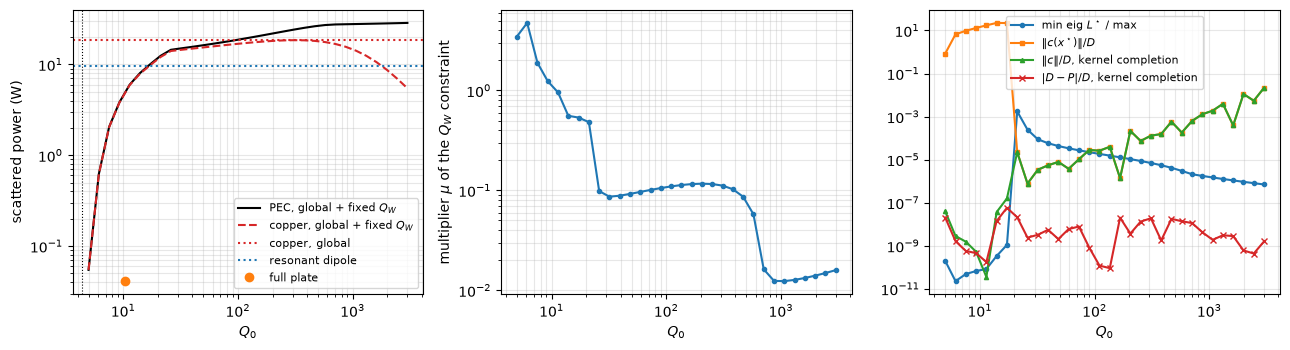

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
ax = axes[0]
ax.loglog(Q0sweep, Dsweep, 'k-', label=r'PEC, global + fixed $Q_W$')
ax.loglog(Q0sweep, Dcu, '--', c='tab:red', label=r'copper, global + fixed $Q_W$')
ax.axhline(Qcu.current_dual, ls=':', c='tab:red', label='copper, global')
ax.axhline(Pdip, ls=':', c='tab:blue', label='resonant dipole')
ax.plot(evalQW(Ifull), Pfull, 'o', c='tab:orange', label='full plate')
ax.axvline(QWmin, ls=':', c='k', lw=0.8)
ax.set_xlabel(r'$Q_0$'); ax.set_ylabel('scattered power (W)'); ax.legend(fontsize=8); ax.grid(True, which='both', alpha=0.3)
ax = axes[1]
ax.loglog(Q0sweep, [r["mu"] for r in sweep], 'o-', ms=3)
ax.set_xlabel(r'$Q_0$'); ax.set_ylabel(r'multiplier $\mu$ of the $Q_W$ constraint'); ax.grid(True, which='both', alpha=0.3)
ax = axes[2]
ax.loglog(Q0sweep, [r["lam"][0]/r["lam"][-1] for r in sweep], 'o-', ms=3, label=r'min eig $L^\star$ / max')
ax.loglog(Q0sweep, [np.linalg.norm(r["res0"])/r["D"] for r in sweep], 's-', ms=3, label=r'$\|c(x^\star)\|/D$')
ax.loglog(Q0sweep, [max(np.linalg.norm(r["res1"])/r["D"], 1e-16) for r in sweep], '^-', ms=3, label=r'$\|c\|/D$, kernel completion')
ax.loglog(Q0sweep, [max(abs(r["gap"]), 1e-16) for r in sweep], 'x-', ms=4, label=r'$|D - P|/D$, kernel completion')
ax.set_xlabel(r'$Q_0$'); ax.legend(fontsize=8); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

## GCD and the full local bound at selected $Q_0$

As in `maxScatFixQ.ipynb`, with the multipliers started from $\tfrac12 + \mu_0$ on the real power constraints (global, or every pointwise one in
the full local problem) and $\mu_0$ on $Q_W$. A completed dual current of the full local problem with zero pointwise violation would be a PEC
structure.

In [9]:
Q0sel = [50, 25, 18, 12]
Ngcd = 20 # number of GCD iterations

gcd = {}
for Q0 in Q0sel:
    Qg = buildQCQP(PlistGlob, Q0)
    Qg.solve_current_dual_problem(method='newton', init_lags=np.array([0.5 + mu0, 0.0, mu0]), opt_params=opt_params)
    glb = copy.deepcopy(Qg)
    gcd_params = GCDHyperparameters(max_proj_cstrt_num=2 + 2*Ngcd,
        max_gcd_iter_num=Ngcd,
        gcd_iter_period=Ngcd + 1, # no early termination
        opt_params=opt_params)
    t1 = time.time()
    with contextlib.redirect_stdout(io.StringIO()): # silence the per-iteration GCD output
        Qg.run_gcd(gcd_params)
    gcd[Q0] = dict(globQ=glb, Q=Qg, **dualReport(f"GCD {Ngcd}, Q0 {Q0}", Qg, time.time() - t1))

GCD 20, Q0 50: D 1.579377e+01 W, mu +9.082e-02, min eig L* / max 2.7e-12, kernel dim 1, ||c||/D: x* 8.1e-02 -> completed 8.1e-04, (D - P(I))/D -3.8e-06, Q_W(I) 50.00, max|w_i| / |I^H V| 1.0e+01, 17.0s


GCD 20, Q0 25: D 1.362289e+01 W, mu +1.889e-01, min eig L* / max 1.7e-11, kernel dim 1, ||c||/D: x* 2.2e-01 -> completed 1.6e-03, (D - P(I))/D -4.6e-04, Q_W(I) 25.00, max|w_i| / |I^H V| 3.2e+00, 26.3s


GCD 20, Q0 18: D 1.055707e+01 W, mu +5.281e-01, min eig L* / max 8.4e-10, kernel dim 1, ||c||/D: x* 8.1e-01 -> completed 9.7e-04, (D - P(I))/D -1.3e-03, Q_W(I) 18.00, max|w_i| / |I^H V| 3.6e+00, 32.5s


GCD 20, Q0 12: D 6.115689e+00 W, mu +9.313e-01, min eig L* / max 1.6e-11, kernel dim 2, ||c||/D: x* 3.7e-01 -> completed 3.8e-04, (D - P(I))/D +8.6e-03, Q_W(I) 12.00, max|w_i| / |I^H V| 5.3e-01, 34.4s


In [10]:
Pdiags = np.column_stack([np.eye(Ndes, dtype=complex), 1j*np.eye(Ndes, dtype=complex)])
PlistAll = [sp.diags(Pdiags[:, i]) for i in range(Pdiags.shape[1])]
print(f"number of projector constraints: {len(PlistAll)}")

full_opt_params = OptimizationHyperparameters(opttol=1e-10,
    gradConverge=True,
    min_inner_iter=10,
    max_restart=30,
    penalty_ratio=1e-3,
    penalty_reduction=0.01,
    break_iter_period=5,
    verbose=0)

loc = {}
for Q0 in Q0sel:
    Ql = buildQCQP(PlistAll, Q0)
    lags_init = np.zeros(2*Ndes + 1)
    lags_init[:Ndes] = 0.5 + mu0 # on all real power constraints
    lags_init[-1] = mu0
    t1 = time.time()
    Ql.solve_current_dual_problem(method='newton', init_lags=lags_init, opt_params=full_opt_params)
    loc[Q0] = dict(Q=Ql, **dualReport(f"full local, Q0 {Q0}", Ql, time.time() - t1))

number of projector constraints: 466


full local, Q0 50: D 1.565774e+01 W, mu +9.448e-02, min eig L* / max 2.7e-13, kernel dim 4, ||c||/D: x* 6.6e+00 -> completed 5.4e+00, (D - P(I))/D -1.5e-05, Q_W(I) 44.57, max|w_i| / |I^H V| 4.6e-01, 44.9s


full local, Q0 25: D 1.353129e+01 W, mu +1.786e-01, min eig L* / max 3.6e-14, kernel dim 4, ||c||/D: x* 8.8e+00 -> completed 7.8e+00, (D - P(I))/D -3.4e-04, Q_W(I) 21.59, max|w_i| / |I^H V| 8.6e-01, 37.0s


full local, Q0 18: D 1.054539e+01 W, mu +5.263e-01, min eig L* / max 4.0e-13, kernel dim 3, ||c||/D: x* 3.5e+00 -> completed 2.9e+00, (D - P(I))/D +1.1e-03, Q_W(I) 10.24, max|w_i| / |I^H V| 3.1e-01, 33.2s


full local, Q0 12: D 6.053458e+00 W, mu +9.367e-01, min eig L* / max 6.7e-13, kernel dim 4, ||c||/D: x* 2.6e+00 -> completed 1.8e+00, (D - P(I))/D +2.3e-01, Q_W(I) 8.75, max|w_i| / |I^H V| 1.6e-01, 39.6s


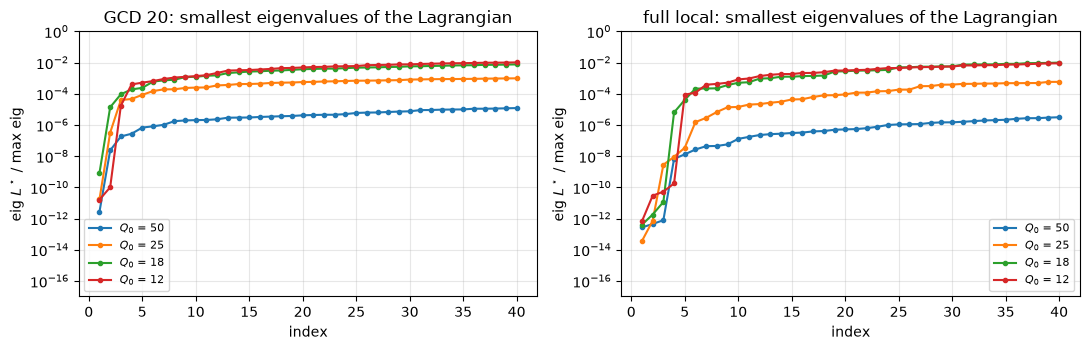

   Q0 |    global       GCD     local (W) | kernel GCD/local | #eig < 1e-6 max | max|w|/|IV| GCD/local | (D - P)/D GCD/local (completed)
   50 |   16.2654   15.7938   15.6577     |      1 /   4     |      6 /  24    | 1.0e+01 / 4.6e-01   | -3.8e-06 / -1.5e-05
   25 |   14.3546   13.6229   13.5313     |      1 /   4     |      2 /   5    | 3.2e+00 / 8.6e-01   | -4.6e-04 / -3.4e-04
   18 |   10.5612   10.5571   10.5454     |      1 /   3     |      1 /   3    | 3.6e+00 / 3.1e-01   | -1.3e-03 / +1.1e-03
   12 |    6.6086    6.1157    6.0535     |      2 /   4     |      2 /   4    | 5.3e-01 / 1.6e-01   | +8.6e-03 / +2.3e-01


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, res, title in [(axes[0], gcd, f'GCD {Ngcd}'), (axes[1], loc, 'full local')]:
    for Q0, r in res.items():
        ax.semilogy(np.arange(1, 41), r["lam"][:40]/r["lam"][-1], '.-', label=f'$Q_0$ = {Q0}')
    ax.set_xlabel('index'); ax.set_ylabel(r'eig $L^\star$ / max eig'); ax.set_title(f'{title}: smallest eigenvalues of the Lagrangian')
    ax.set_ylim(1e-17, 1); ax.legend(fontsize=8); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

print(f"{'Q0':>5s} | {'global':>9s} {'GCD':>9s} {'local':>9s} (W) | kernel GCD/local | #eig < 1e-6 max | "
      f"max|w|/|IV| GCD/local | (D - P)/D GCD/local (completed)")
for Q0 in Q0sel:
    g, l = gcd[Q0], loc[Q0]
    wv = [np.abs(localViolation(VtoI(r["x"]))).max()/np.abs(VtoI(r["x"]).conj() @ Vinc) for r in (g, l)]
    ns = [np.count_nonzero(r["lam"] < 1e-6*r["lam"][-1]) for r in (g, l)]
    print(f"{str(Q0):>5s} | {g['globQ'].current_dual:9.4f} {g['D']:9.4f} {l['D']:9.4f}     | {g['K']:6d} / {l['K']:3d}     | "
          f"{ns[0]:6d} / {ns[1]:3d}    | {wv[0]:.1e} / {wv[1]:.1e}   | {g['gap']:+.1e} / {l['gap']:+.1e}")

## Inference of PEC structures

Every dual solution (global, GCD, full local) at every $Q_0$ is turned into a PEC structure. The bound at fixed $Q_W$ applies to every PEC
structure with that $Q_W$ (and, since $\mu > 0$, to every structure with a lower $Q_W$).

In [12]:
inf = {}
t1 = time.time()
for Q0 in Q0sel:
    for kind, Q, x in [("global", gcd[Q0]["globQ"], None), (f"GCD {Ngcd}", gcd[Q0]["Q"], gcd[Q0]["x"]), ("full local", loc[Q0]["Q"], loc[Q0]["x"])]:
        if x is None:
            x = completeKernel(Q)[0]
        inf[(kind, Q0)] = dict(inferAll(Q, x), D=Q.current_dual, x=x)
print(f"inference: {time.time()-t1:.1f}s")

print(f"{'dual':>10s} {'Q0':>4s} {'D (W)':>7s} | {'impedance form':>18s} | Lagrangian fit: start, J/D, relaxed P, binary P (Q_W, Q) | smallest J: start, P")
for (kind, Q0), r in inf.items():
    pf, lf, sj = r["impedance form"], r["Lagrangian fit"], r["smallest J"]
    print(f"{kind:>10s} {Q0:4d} {r['D']:7.3f} | {pf['P']:.2e} ({pf['QW']:6.1f}) | {lf['start']:14s}, {lf['J']/r['D']:.2f}, "
          f"{lf['Prelax']:.2e}, {lf['P']:.3e} W ({lf['QW']:.1f}, {lf['Q']:.1f}) | {sj['start']:14s}, {sj['P']:.3e} W")

# check of the Lagrangian identity for the best design: P = D - J - lambda . c(x)
kind, Q0 = max(inf, key=lambda k: inf[k]["Lagrangian fit"]["P"])
Qbest = {"global": gcd[Q0]["globQ"], f"GCD {Ngcd}": gcd[Q0]["Q"], "full local": loc[Q0]["Q"]}[kind]
lhs, rhs = lagIdentity(Qbest, inf[(kind, Q0)]["Lagrangian fit"]["I"])
print(f"best design from {kind}, Q0 {Q0}: D - J - lambda.c = {lhs:.6e} W, P = {rhs:.6e} W")

inference: 127.3s
      dual   Q0   D (W) |     impedance form | Lagrangian fit: start, J/D, relaxed P, binary P (Q_W, Q) | smallest J: start, P
    global   50  16.265 | 5.91e-02 (  15.1) | full plate    , 0.36, 8.80e+00, 9.463e+00 W (22.8, 23.0) | full plate    , 9.463e+00 W
    GCD 20   50  15.794 | 4.45e-02 (  11.5) | uniform 0.5   , 0.36, 9.02e+00, 9.017e+00 W (19.1, 19.1) | uniform 0.5   , 9.017e+00 W
full local   50  15.658 | 1.86e-01 (  25.2) | full plate    , 0.44, 5.98e+00, 8.235e+00 W (20.8, 20.9) | full plate    , 8.235e+00 W
    global   25  14.355 | 6.15e-02 (  14.7) | uniform 0.5   , 0.30, 9.61e+00, 9.615e+00 W (21.3, 21.4) | uniform 0.5   , 9.615e+00 W
    GCD 20   25  13.623 | 1.29e-01 (  59.4) | impedance form, 0.45, 3.34e+00, 1.104e+01 W (81.0, 81.3) | impedance form, 1.104e+01 W
full local   25  13.531 | 7.28e-02 (  16.5) | uniform 0.5   , 0.44, 6.63e+00, 7.037e+00 W (19.2, 19.3) | uniform 0.5   , 7.037e+00 W
    global   18  10.561 | 4.31e-02 (  11.0) | impedance f

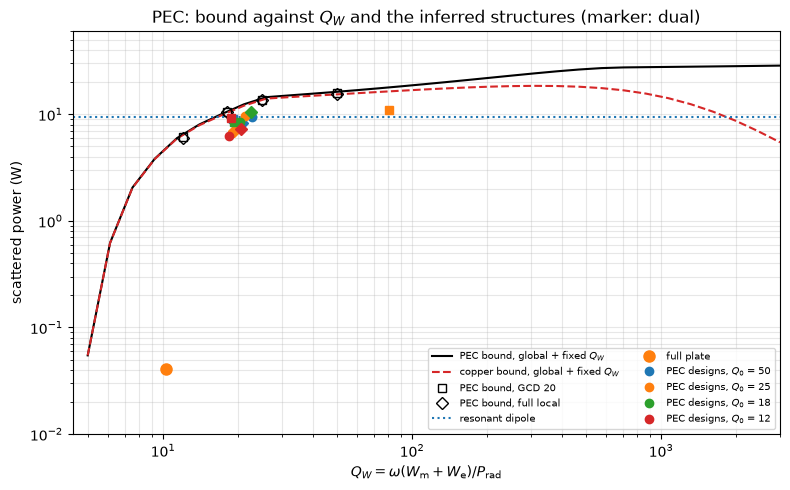

    global   50: design P 9.463 W at Q_W 22.8: 0.58 of its dual bound, 0.72 of the PEC bound at its own Q_W (13.18 W)
    GCD 20   50: design P 9.017 W at Q_W 19.1: 0.57 of its dual bound, 0.80 of the PEC bound at its own Q_W (11.23 W)
full local   50: design P 8.235 W at Q_W 20.8: 0.53 of its dual bound, 0.67 of the PEC bound at its own Q_W (12.23 W)
    global   25: design P 9.615 W at Q_W 21.3: 0.67 of its dual bound, 0.77 of the PEC bound at its own Q_W (12.51 W)
    GCD 20   25: design P 11.040 W at Q_W 81.0: 0.81 of its dual bound, 0.62 of the PEC bound at its own Q_W (17.89 W)
full local   25: design P 7.037 W at Q_W 19.2: 0.52 of its dual bound, 0.62 of the PEC bound at its own Q_W (11.33 W)
    global   18: design P 8.474 W at Q_W 20.4: 0.80 of its dual bound, 0.71 of the PEC bound at its own Q_W (12.00 W)
    GCD 20   18: design P 8.437 W at Q_W 19.2: 0.80 of its dual bound, 0.75 of the PEC bound at its own Q_W (11.32 W)
full local   18: design P 10.446 W at Q_W 22.6: 0.99 of

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(Q0sweep, Dsweep, 'k-', label=r'PEC bound, global + fixed $Q_W$')
ax.loglog(Q0sweep, Dcu, '--', c='tab:red', label=r'copper bound, global + fixed $Q_W$')
for kind, mk in [(f"GCD {Ngcd}", 's'), ("full local", 'D')]:
    res = gcd if kind != "full local" else loc
    ax.plot(Q0sel, [res[q]["D"] for q in Q0sel], mk, mfc='none', c='k', label=f'PEC bound, {kind}')
ax.axhline(Pdip, ls=':', c='tab:blue', label='resonant dipole')
ax.plot(evalQW(Ifull), Pfull, 'o', c='tab:orange', ms=8, label='full plate')
colors = {Q0: f'C{k}' for k, Q0 in enumerate(Q0sel)}
markers = {"global": 'o', f"GCD {Ngcd}": 's', "full local": 'D'}
for (kind, Q0), r in inf.items():
    lf = r["Lagrangian fit"]
    if lf["P"] > 0:
        ax.plot(lf["QW"], lf["P"], markers[kind], c=colors[Q0], ms=6)
for Q0 in Q0sel:
    ax.plot([], [], 'o', c=colors[Q0], label=f'PEC designs, $Q_0$ = {Q0}')
ax.set_xlabel(r'$Q_W = \omega(W_\mathrm{m} + W_\mathrm{e}) / P_\mathrm{rad}$'); ax.set_ylabel('scattered power (W)')
ax.set_xlim(QWmin, 3000); ax.set_ylim(1e-2, 60)
ax.legend(fontsize=7, ncol=2); ax.grid(True, which='both', alpha=0.3)
ax.set_title('PEC: bound against $Q_W$ and the inferred structures (marker: dual)')
plt.tight_layout(); plt.show()

DofQ = lambda q: np.interp(np.log(q), np.log(Q0sweep), Dsweep)
for (kind, Q0), r in inf.items():
    lf = r["Lagrangian fit"]
    if lf["P"] > 0:
        print(f"{kind:>10s} {Q0:4d}: design P {lf['P']:.3f} W at Q_W {lf['QW']:.1f}: {lf['P']/r['D']:.2f} of its dual bound, "
              f"{lf['P']/DofQ(lf['QW']):.2f} of the PEC bound at its own Q_W ({DofQ(lf['QW']):.2f} W)")

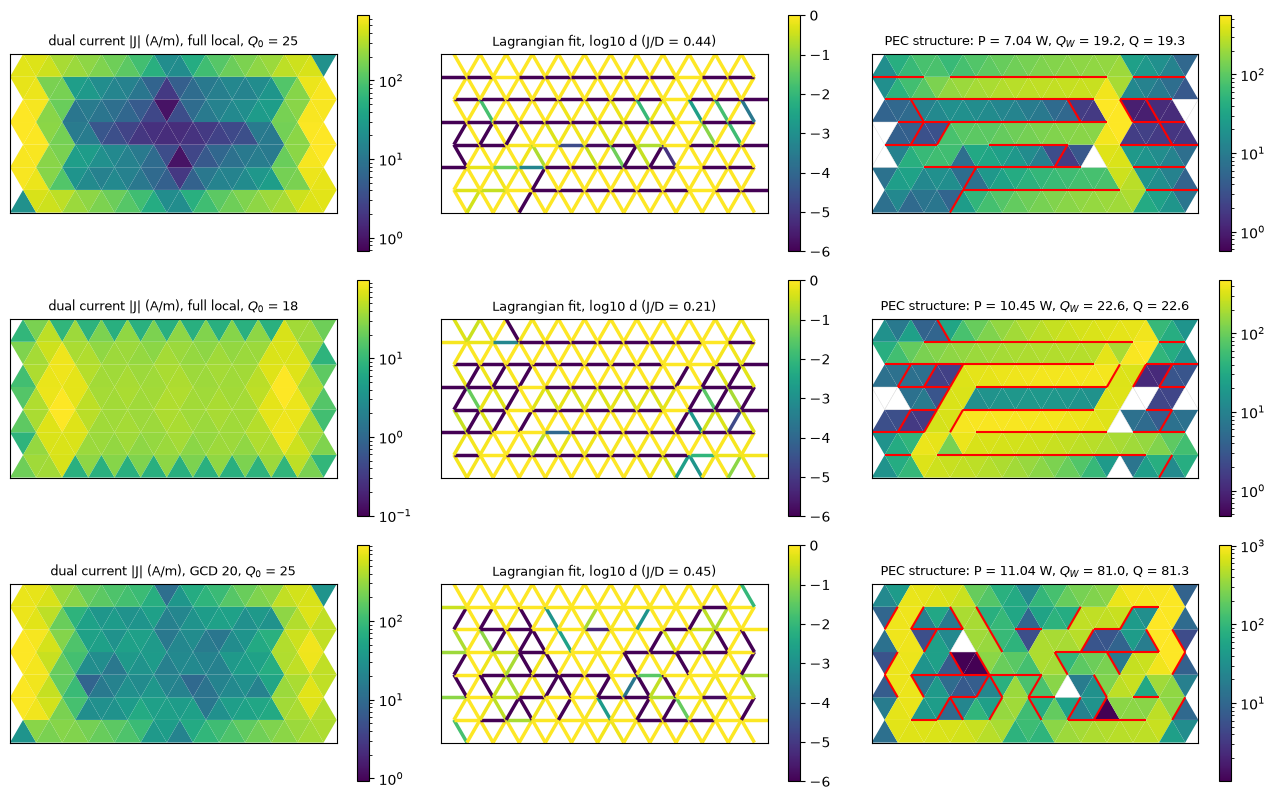

In [14]:
best = max(inf, key=lambda k: inf[k]["Lagrangian fit"]["P"])
show = [("full local", 25), ("full local", 18)] + ([best] if best not in [("full local", 25), ("full local", 18)] else [("global", 18)])
fig, axes = plt.subplots(len(show), 3, figsize=(13, 2.7*len(show)))
for row, key in zip(axes, show):
    kind, Q0 = key
    lf = inf[key]["Lagrangian fit"]
    name = f"{kind}, $Q_0$ = {Q0}"
    plt.colorbar(plotStructure(row[0], np.ones(Ndes, dtype=bool), VtoI(inf[key]["x"]), f"dual current |J| (A/m), {name}"), ax=row[0])
    plt.colorbar(plotDensity(row[1], lf["d"], f"Lagrangian fit, log10 d (J/D = {lf['J']/inf[key]['D']:.2f})"), ax=row[1])
    plt.colorbar(plotStructure(row[2], lf["keep"], lf["I"],
                               f"PEC structure: P = {lf['P']:.2f} W, $Q_W$ = {lf['QW']:.1f}, Q = {lf['Q']:.1f}"), ax=row[2])
plt.tight_layout(); plt.show()

## Conclusions

**Positive definiteness from $\omega W$ alone.** Without the $Q_W$ constraint no PSD point of the PEC Lagrangian exists ($R_0$ has rank 29 of 233,
the reactive term is indefinite). With it, the start $\lambda_\mathrm{re} = \tfrac12 + \mu_0$, $\mu_0 = 1$ gives exactly $A = \mu_0 W^H \omega W W / (2Q_0) \succ 0$,
and the optimal $\mu$ stays positive over the whole sweep ($Q_0$ = 5–3000), so the front bounds every PEC structure with $Q_W \leq Q_0$.

**Bound.** The PEC and copper fronts coincide at low $Q_W$ (ratio 1.00 at $Q_0 = 5$, 1.01 at 11, 1.03 at 26): below $Q_W \approx 30$ the ohmic loss is
irrelevant and the stored energy alone limits scattering. At high $Q_W$ they separate: copper peaks at 18.5 W ($Q_W \approx 320$) and then falls,
while the PEC bound keeps growing slowly (24.2 W at $Q_0 = 310$, 28.6 W at 3000; 1.3 and 2.7 times copper at $Q_0$ = 310 and 1615).
The pointwise constraints tighten the global bound by 0.2–8 % (GCD 20, full local).

**Strong duality.** The global fixed-$Q_W$ QCQP has zero gap at every $Q_0$: interior for $Q_0 \geq 21$, and the hard case with a one-dimensional
kernel and a feasible rank-one completion ($|D - P|/D < 10^{-7}$) for $Q_0 \leq 17$. GCD 20 is close to strongly dual (completed $\|c\|/D \leq 1.6\cdot 10^{-3}$,
gap below 1 %). The full local dual stays on the PSD boundary with a 3–4-dimensional kernel and no feasible completion ($\|c\|/D$ of order one),
the same picture as copper: the PEC full local problem is not strongly dual, though the dual current is closer to a structure
($\max|w_i|/|I^H V|$ 0.16–0.86).

**Inference.** The pointwise impedance form fails (at most 1 W). The Lagrangian solution fit with the PEC density model ($\kappa = 10^{-3}\overline{|Z_{0,ii}|}$),
keeping the start with the best exact power, gives meander structures of 6.3–11.0 W from every dual. Near the target the best is 10.45 W at
$Q_W = 22.6$ (full local, $Q_0 = 18$), 0.80 of the PEC bound at its own $Q_W$ and 1.1 times the resonant dipole; GCD 20 at $Q_0 = 25$ gives 11.0 W but at
$Q_W = 81$, far above the target. Most designs land at $Q_W \approx 18$–$23$ regardless of $Q_0$ and reach 0.58–0.84 of the PEC bound at their own
$Q_W$; for $Q_0 = 12$ they violate the fixed $Q_W$, so they can exceed their own dual bound. Compared with copper (best 8.96 W at $Q_W = 18.5$), the
PEC designs are 0.5–1.5 W better at similar $Q_W$, slightly more than the 1–3 % difference of the bounds there, reflecting run-to-run
variation of the fit as much as the missing loss.